# **Описание файла**

В данном ноутбуке реализован этап построения базовой (baseline) модели для задачи регрессии годовых медицинские расходы клиентов. Цель этапа — сформировать воспроизводимый пайплайн предобработки данных и получить объективный ориентир качества, относительно которого в дальнейшем будут оцениваться улучшения (новые признаки, ансамбли, подбор гиперпараметров).

На текущем этапе решаются следующие задачи:

- **Предобработка данных**: очистка от очевидных аномалий, обработка пропусков, приведение типов и кодирование категориальных признаков с сохранением семантики (в том числе бинарных признаков).
- **Подготовка выборок**: формирование обучающей и тестовой подвыборок с учётом дисбаланса классов, применение стратификации по целевой переменной, а при необходимости — кросс-валидация с `StratifiedKFold`.
- **Построение baseline-моделей**: реализация простых, но информативных моделей, позволяющих оценить принципиальную предсказуемость целевой переменной на имеющихся признаках:
  - логистическая регрессия (`LogisticRegression`) как интерпретируемая базовая модель;
  - простое дерево решений небольшой глубины (`DecisionTreeClassifier`) для быстрой оценки нелинейностей.
- **Оценка качества**: расчёт ключевых метрик (MAE, MSE, RMSE, R1), анализ матрицы ошибок и сравнение результатов моделей между собой и с наивной стратегией.

Полученные результаты будут использованы как точка отсчёта для последующих экспериментов: добавления новых признаков, применения методов борьбы с дисбалансом (SMOTE, `class_weight`), а также более сложных моделей (RandomForest, LGBMClassifier). Все этапы реализованы с учётом воспроизводимости: зафиксированы `random_state`, последовательность шагов предобработки и схема валидации.


# **Импорт основных библиотек**

In [63]:
# импорт модулей/библиотек для обработки данных
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, KFold
from sklearn.metrics import roc_auc_score, f1_score, classification_report
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin
import seaborn as sns
from my_def_and_plot import *
import random
from scipy.stats import randint, uniform, loguniform
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.tree import DecisionTreeRegressor

from sklearn.linear_model import Ridge
from scipy.stats import uniform, randint
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error


In [2]:
# импорт необходимого окружения для визуализации
# отключим предупреждения Anaconda
import warnings
warnings.simplefilter('ignore')

# будем отображать графики прямо в jupyter'e
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
#графики в svg выглядят более четкими
%config InlineBackend.figure_format = 'svg' 

#увеличим дефолтный размер графиков
from pylab import rcParams
rcParams['figure.figsize'] = 8, 5
import pandas as pd

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

# **1. Препроцессинг данных**

**Препроцессинг данных можно разделить на две основные категории:**

* Общие преобразования – применяются ко всему датасету до разделения на train и test.
* Индивидуальные преобразования – выполняются отдельно для тренировочной и тестовой выборок.

`Почему такое разделение необходимо?`

Некоторые преобразования требуют расчета статистик (например, замена пропусков медианой, стандартизация, частотное кодирование) или даже обучения вспомогательных моделей (например, KNN для импутации пропущенных значений). Если применить такие преобразования ко всему датасету до разделения, это приведет к data leakage (утечке данных).

`Что такое data leakage и чем он опасен?`

Data leakage возникает, когда информация из тестового набора неявно влияет на preprocessing тренировочных данных (например, при расчете среднего или обучении encoder'а). В результате:

Модель получает доступ к данным, которых не должно "знать" в реальных условиях;
Оценки качества становятся завышенными, но на новых данных модель работает хуже.
Как избежать утечки данных?

Сначала разделять данные на train и test (или использовать кросс-валидацию).
Обучать preprocessing-алгоритмы (импутеры, энкодеры, скейлеры) только на train.
Применять обученные преобразования к test, без пересчета статистик.
Крайне рекомендуется использовать пайплайны (например, sklearn.pipeline.Pipeline), которые автоматически следят за корректным порядком преобразований.

`Какие преобразования можно применять ко всему датасету?`

Те, что не зависят от статистик и не требуют обучения:

* Удаление дубликатов;
* Исправление очевидных аномалий (например, отрицательный возраст);
* Разовые преобразования (изменение формата даты, переименование столбцов);
* Фильтрация строк/столбцов, не связанная с целевой переменной;
* Такой подход помогает избежать дублирования кода, сохраняя при этом валидность эксперимента.

## **1.1 Общие преобразования**

In [4]:
# выгрузка данных
df = pd.read_csv('medical_insurance.csv')
# создадим независимую копию исходного DataFrame df
df_preprocessed = df.copy()

# удаление признков с мультиколлинеарностью


Обнаружена мультиколлинеарность между входными признаками:

* `annual_premium`(Годовой взнос) и `monthly_premium`(Ежемесячный взнос), но они должны быть удалены оба;
* `diabetes`(Диабет) и `hba1c`(Гликированный гемоглобин);
* `is_high_risk`(Высокий риск) и `risk_score`(Оценка риска).

**Исключение признаков с риском утечки данных (Data Leakage)**

Для обеспечения корректности прогноза целевой переменной annual_medical_cost из матрицы признаков были исключены переменные, функционально связанные с целевой величиной или используемые для её расчёта.

**В частности, удалены следующие признаки:**

* claims_count, avg_claim_amount: их произведение напрямую аппроксимирует сумму медицинских расходов, что приводит к «подглядыванию» в целевую переменную;
* risk_score: представляет собой внутреннюю оценку риска страховой компании, которая уже учитывает ожидаемые выплаты; использование этого признака делает задачу тривиальной;
* annual_premium, monthly_premium: страховые премии формируются на основе оценки рисков и ожидаемых расходов, их использование нарушает причинно-следственную логику прогноза;

После исключения указанных признаков модель вынуждена опираться на демографические, медицинские и поведенческие характеристики клиентов, что позволяет выявить реальные закономерности влияния факторов на медицинские расходы.



In [5]:
# признаки, которые хотели удалить, но из-за отсутствия спецификации данных удалили только некоторые...
# удаление признков с мультиколлинеарностью `annual_premium`,`monthly_premium`, `hba1c` и `is_high_risk`...
''' list_delete = [
    'claims_count',         
    'avg_claim_amount',      
    'risk_score',           
    'annual_premium',        
    'monthly_premium',        
    'total_claims_paid'     
] '''

" list_delete = [\n    'claims_count',         \n    'avg_claim_amount',      \n    'risk_score',           \n    'annual_premium',        \n    'monthly_premium',        \n    'total_claims_paid'     \n] "

In [6]:
# удаление признков с мультиколлинеарностью `annual_premium`,`monthly_premium`, `hba1c` и `is_high_risk`...
list_delete = [              
    'annual_premium',        
    'monthly_premium',
    'hba1c',
    'is_high_risk',
    'dependents'   
]

df_preprocessed = df_preprocessed.drop(list_delete, axis=1)

### **1.1.1 Работа по признаку alcohol_freq**

In [7]:
# количесвто пропусков в признаке alcohol_freq
df_preprocessed['alcohol_freq'].isna().sum()

30083

In [8]:
# уникальные значения признак alcohol_freq
df_preprocessed['alcohol_freq'].value_counts()

alcohol_freq
Occasional    45078
Weekly        19833
Daily          5006
Name: count, dtype: int64

Считаем, что пропуски не случайные и их надо заполнить значением Occasional (ибо человек иногда все-таки выпивает)...

In [9]:
# замена пропуска наиболее логичным значением
df_preprocessed['alcohol_freq'].fillna('Occasional', inplace=True)
# количесвто пропусков в признаке alcohol_freq
df_preprocessed['alcohol_freq'].isna().sum()

0

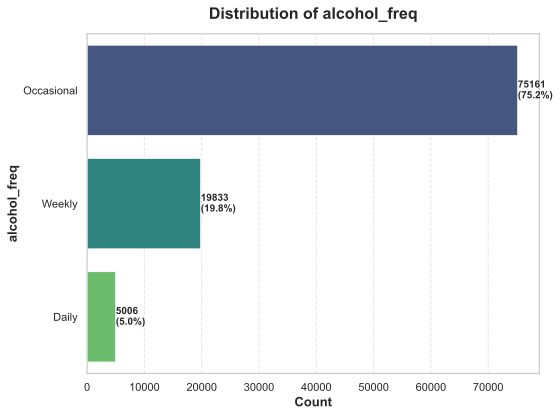

Статистика для 'alcohol_freq':
  Unique categories: 3
  Total count: 100000

Top categories:
  Occasional: 75161 (75.2%)
  Weekly: 19833 (19.8%)
  Daily: 5006 (5.0%)


In [10]:
# воспользуемся столбчатой диаграммой для визуализации
plot_bar_categorical(df_preprocessed,'alcohol_freq')

* нет «микрокатегорий»: все группы достаточно крупные (минимум 5 %), поэтому объединять в «Other» не нужно;
* для alcohol_freq лучше всего порядковое (ordinal) кодирование, а не One‑Hot.

### **1.1.2 Работа по признаку age**

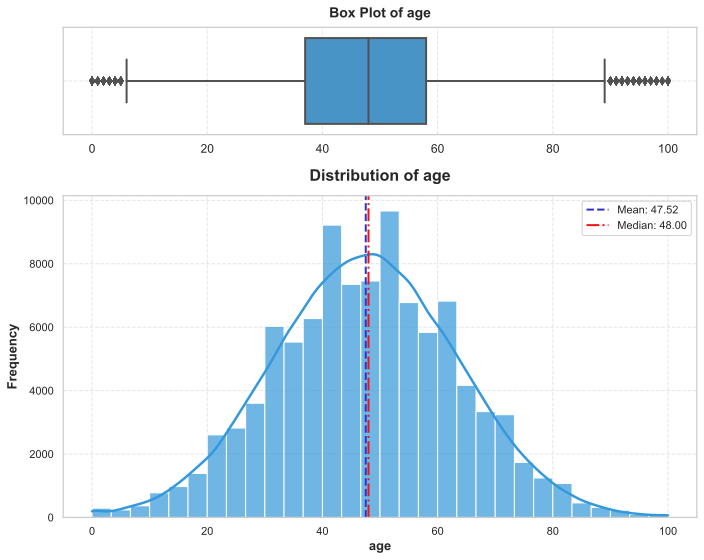

Статистика для 'age':
  Mean:   47.52
  Median: 48.00
  Std:    15.99
  Min:    0.00
  Max:    100.00
  Count:  100000
  Q1:     37.00
  Q3:     58.00
  IQR:    21.00


In [11]:
# до удаления клиентов с возрастом моложе 18 лет
plot_hist_numeric(df_preprocessed, 'age')

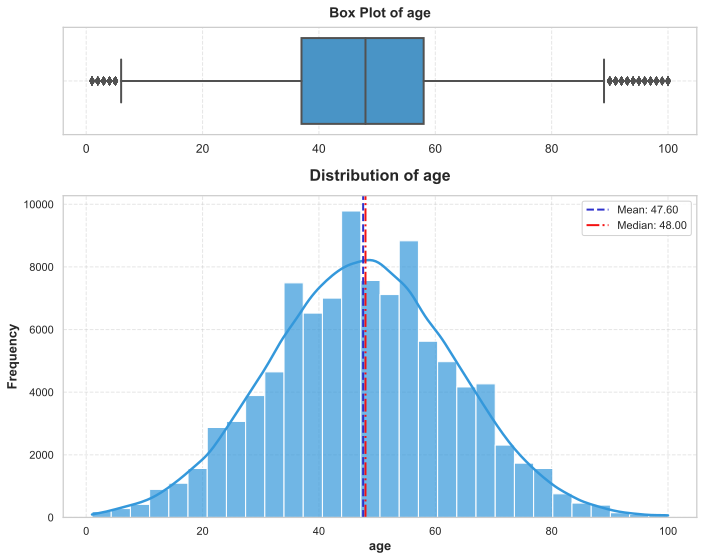

Статистика для 'age':
  Mean:   47.60
  Median: 48.00
  Std:    15.88
  Min:    1.00
  Max:    100.00
  Count:  99835
  Q1:     37.00
  Q3:     58.00
  IQR:    21.00


In [12]:
# удаляем выбросы
df_preprocessed = df_preprocessed[df_preprocessed['age']!=0]
# после удаления клиентов с возрастом моложе 18 лет
plot_hist_numeric(df_preprocessed, 'age')

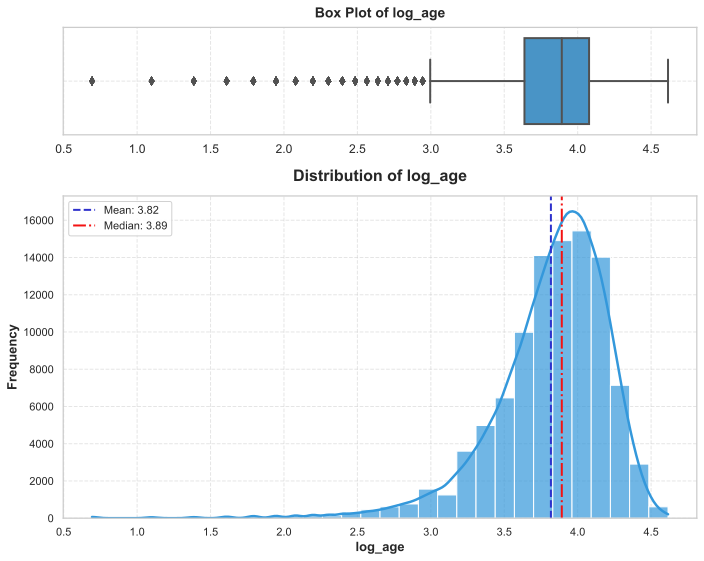

Статистика для 'log_age':
  Mean:   3.82
  Median: 3.89
  Std:    0.40
  Min:    0.69
  Max:    4.62
  Count:  99835
  Q1:     3.64
  Q3:     4.08
  IQR:    0.44


In [13]:
# логарифмирование признака 
df_preprocessed['log_age'] = np.log1p(df_preprocessed['age'])
# удалим duration из датафремйа, чтоб нивелировать перекос
df_preprocessed = df_preprocessed.drop(columns=['age'])
# вывод гистограммы
plot_hist_numeric(df_preprocessed, 'log_age')

* Удалили клиентов моложе 18 лет (считаем, что клиент должен работать => клиент должен быть страше 18 лет);
* Видим перекос вправо, проводим логарифмирование и добавление новго признака (с удалением исходного age).

### **1.1.3 Работа по признаку income**

--- Статистика для 'income' ---


count    9.983500e+04
mean     4.987054e+04
std      4.679521e+04
min      1.100000e+03
25%      2.110000e+04
50%      3.620000e+04
75%      6.220000e+04
max      1.061800e+06
Name: income, dtype: float64

Axes(0.0857396,0.0396;0.88951x0.851133)


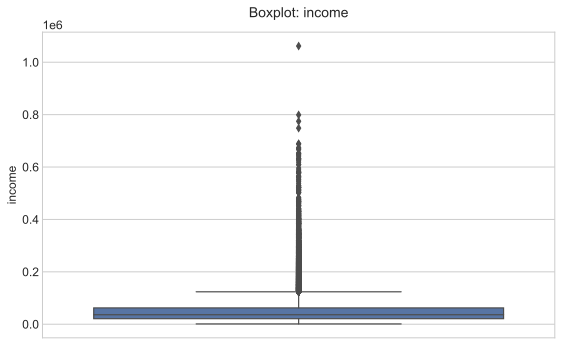

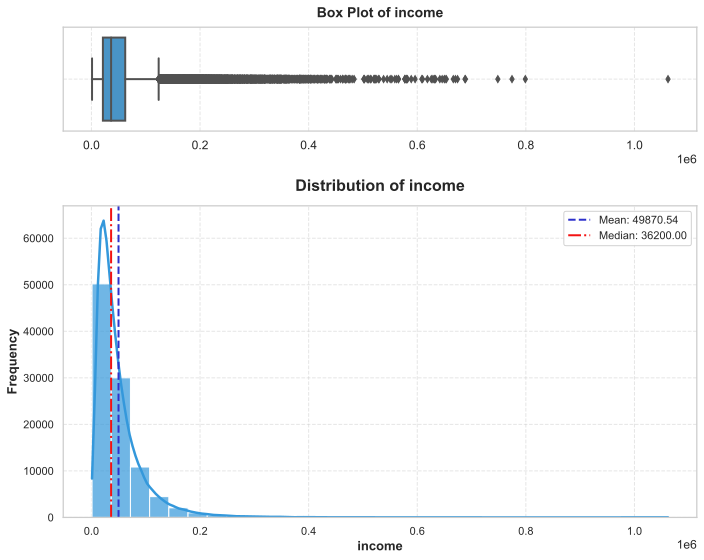

Статистика для 'income':
  Mean:   49870.54
  Median: 36200.00
  Std:    46795.21
  Min:    1100.00
  Max:    1061800.00
  Count:  99835
  Q1:     21100.00
  Q3:     62200.00
  IQR:    41100.00
None


In [14]:
# вывод боксплота до логарифмирования для признака
print(plot_box_and_describe_single(df_preprocessed, 'income'))
# гистограмма income до логарифмирование
print(plot_hist_numeric(df_preprocessed, 'income'))

In [15]:
# логарифмирование признака 
df_preprocessed['log_income'] = np.log1p(df_preprocessed['income'])
# удалим duration из датафремйа, чтоб нивелировать перекос
df_preprocessed = df_preprocessed.drop(columns=['income'])

--- Статистика для 'log_income' ---


count    99835.000000
mean        10.497700
std          0.800413
min          7.003974
25%          9.957076
50%         10.496842
75%         11.038126
max         13.875477
Name: log_income, dtype: float64

Axes(0.0802122,0.0396;0.895038x0.851133)


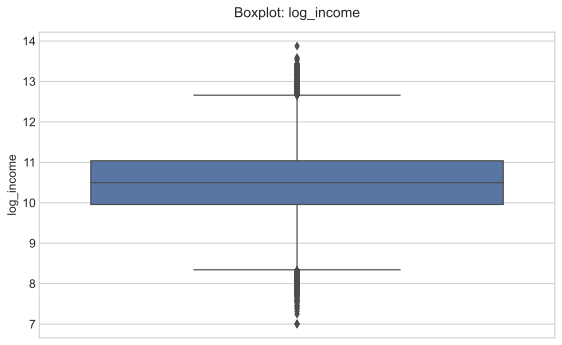

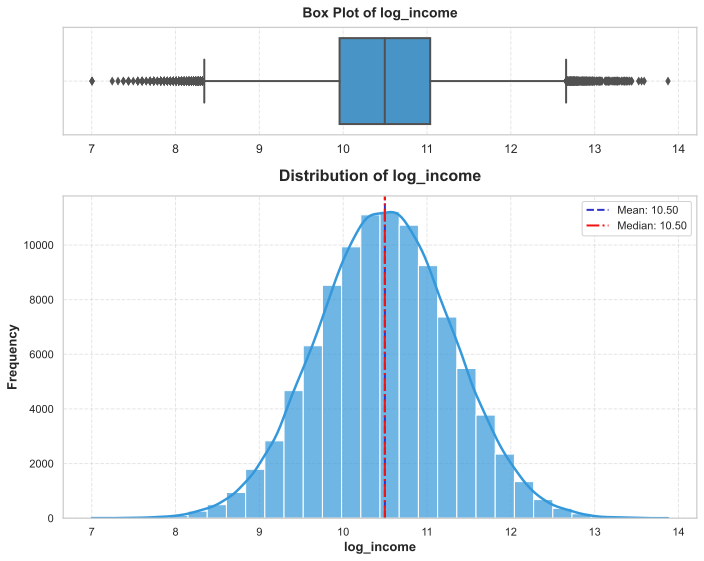

Статистика для 'log_income':
  Mean:   10.50
  Median: 10.50
  Std:    0.80
  Min:    7.00
  Max:    13.88
  Count:  99835
  Q1:     9.96
  Q3:     11.04
  IQR:    1.08
None


In [16]:
# вывод боксплота после логарифмирования для признака
print(plot_box_and_describe_single(df_preprocessed, 'log_income'))
# гистограмма income после логарифмирование
print(plot_hist_numeric(df_preprocessed, 'log_income'))

* Признак income прологарифмирован, удален => новый признак имеет симметричное нормальное распределение...

### **1.1.4 Удаление признака person_id**

In [17]:
# удаление признака
df_preprocessed = df_preprocessed.drop('person_id', axis=1)

### **1.1.5 Работа по признаку sex**

In [18]:
# удалим некорректный класс
df_preprocessed = df_preprocessed[df_preprocessed['sex'] != 'Other']


## **1.2 Разбиение датасета**

In [19]:
# разбиваем признаковое описание на целевой и входные признаки
X = df_preprocessed.drop('annual_medical_cost', axis=1)
y = df_preprocessed['annual_medical_cost']

# разбиваем данные на тренировочную и тестовую выборки
# Разбиваем данные на train и test с соотношением 80 на 20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=SEED 
)

# проверка деления
print(X_train.shape, y_train.shape)
print( X_test.shape, y_test.shape)

(78258, 47) (78258,)
(19565, 47) (19565,)


## **1.3 Индивидуальные преобразования**

In [20]:
# разделим признаки на количесвтенные и качественные признаки
numerical_features = [x for x in df_preprocessed.columns if pd.api.types.is_numeric_dtype(df_preprocessed[x])]
categorical_features = list(set([x for x in df_preprocessed.columns if not pd.api.types.is_numeric_dtype(df_preprocessed[x])]) - set(['deposit']))

# проверка наличия дополнительных признаков
print(numerical_features)
print(categorical_features)

['household_size', 'bmi', 'visits_last_year', 'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs', 'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'deductible', 'copay', 'policy_term_years', 'policy_changes_last_2yrs', 'provider_quality', 'risk_score', 'annual_medical_cost', 'claims_count', 'avg_claim_amount', 'total_claims_paid', 'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd', 'cardiovascular_disease', 'cancer_history', 'kidney_disease', 'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count', 'proc_surgery_count', 'proc_physio_count', 'proc_consult_count', 'proc_lab_count', 'had_major_procedure', 'log_age', 'log_income']
['sex', 'smoker', 'plan_type', 'marital_status', 'employment_status', 'network_tier', 'alcohol_freq', 'urban_rural', 'region', 'education']


In [21]:
# выведем уникальные значения признаков
for i in categorical_features:
    print(f'Уникальные значения признака {i.upper()}:')
    print(df_preprocessed[i].unique())

Уникальные значения признака SEX:
['Female' 'Male']
Уникальные значения признака SMOKER:
['Never' 'Current' 'Former']
Уникальные значения признака PLAN_TYPE:
['PPO' 'POS' 'HMO' 'EPO']
Уникальные значения признака MARITAL_STATUS:
['Married' 'Single' 'Divorced' 'Widowed']
Уникальные значения признака EMPLOYMENT_STATUS:
['Retired' 'Employed' 'Self-employed' 'Unemployed']
Уникальные значения признака NETWORK_TIER:
['Bronze' 'Gold' 'Platinum' 'Silver']
Уникальные значения признака ALCOHOL_FREQ:
['Occasional' 'Weekly' 'Daily']
Уникальные значения признака URBAN_RURAL:
['Suburban' 'Urban' 'Rural']
Уникальные значения признака REGION:
['North' 'Central' 'West' 'South' 'East']
Уникальные значения признака EDUCATION:
['Doctorate' 'No HS' 'HS' 'Some College' 'Masters' 'Bachelors']


**Представленные качесвтенные признаки кодируем следующим образомб, а количественные признаки стандартизируем:**

* One‑Hot Encoding — для номинальных признаков без порядка: plan_type, sex, region, urban_rural, network_tier, marital_status, employment_status;
* Ordinal Encoding — когда категории можно упорядочить по смыслу/рангу: education, alcohol_freq, smoker;
* Binary (0/1) — для бинарных признаков (yes/no, true/false): hypertension, diabetes, is_high_risk и т.п...

In [22]:
# списки признаков (теперь binary_yesno пустой)
cat_ohe = ['sex', 'region', 'urban_rural', 'marital_status', 'employment_status', 'plan_type']
cat_ordinal = ['education', 'alcohol_freq', 'smoker', 'network_tier']
binary_yesno = []  # нет колонок yes/no, поэтому список пустой

num_scale = [
    'household_size', 'dependents', 'bmi',
    'visits_last_year', 'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs',
    'medication_count', 'systolic_bp', 'diastolic_bp',
    'ldl', 'hba1c', 'deductible', 'copay',
    'policy_term_years', 'policy_changes_last_2yrs',
    'provider_quality', 'risk_score',
    'annual_premium', 'monthly_premium',
    'claims_count', 'avg_claim_amount', 'total_claims_paid',
    'chronic_count',
    'proc_imaging_count', 'proc_surgery_count', 'proc_physio_count',
    'proc_consult_count', 'proc_lab_count',
    'log_age', 'log_income',
    'is_high_risk'  # бинарный признак 0/1 теперь здесь — он пройдёт через imputer+scaler
]

edu_order = ['No HS', 'HS', 'Some College', 'Bachelors', 'Masters', 'Doctorate']
alc_order = ['Occasional', 'Weekly', 'Daily']
smk_order = ['Never', 'Former', 'Current']
nt_order = ['Bronze', 'Silver', 'Gold', 'Platinum']


def filter_cols(cols, df):
    return [c for c in cols if c in df.columns]



# функция построения препроцессора (без BinaryMapper)
def build_preprocessor(df):
    ohe_cols = filter_cols(cat_ohe, df)
    ord_cols = filter_cols(cat_ordinal, df)
    bin_cols = filter_cols(binary_yesno, df)  # будет пустым
    num_cols = filter_cols(num_scale, df)    # сюда попадёт is_high_risk, если есть

    ord_cats = []
    for c in ord_cols:
        if c == 'education':
            ord_cats.append(edu_order)
        elif c == 'alcohol_freq':
            ord_cats.append(alc_order)
        elif c == 'smoker':
            ord_cats.append(smk_order)
        elif c == 'network_tier':
            ord_cats.append(nt_order)

    preprocessor = ColumnTransformer(
        transformers=[
            ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ohe_cols),
            ('ordinal', OrdinalEncoder(categories=ord_cats, handle_unknown='use_encoded_value', unknown_value=-1), ord_cols),
            # BinaryMapper убран: колонок yes/no нет
            ('num', SkPipeline(steps=[
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), num_cols)
        ],
        remainder='drop'
    )
    return preprocessor

# инициализация и обучение ТОЛЬКО препроцессор
preprocessor = build_preprocessor(X_train)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# проерка
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

# получаем имена признаков корректно (не вручную!)
ohe_step = preprocessor.named_transformers_['ohe']
ohe_feature_names = ohe_step.get_feature_names_out(filter_cols(cat_ohe, X_train))

ord_cols_used = filter_cols(cat_ordinal, X_train)
bin_cols_used = filter_cols(binary_yesno, X_train)
num_cols_used = filter_cols(num_scale, X_train)

all_feature_names = list(ohe_feature_names) + ord_cols_used + bin_cols_used + num_cols_used

# превращаем в DataFrame (для анализа, визуализации, feature importance и т.п.)
X_train_df = pd.DataFrame(X_train_processed, columns=all_feature_names, index=X_train.index)
X_test_df = pd.DataFrame(X_test_processed, columns=all_feature_names, index=X_test.index)

# проерка
print("X_train_df shape:", X_train_df.shape)
print("X_test_df shape:", X_test_df.shape)

# инициализация переменной с именами признаков
feature_names = X_train_df.columns.to_list()


X_train_processed shape: (78258, 46)
X_test_processed shape: (19565, 46)
X_train_df shape: (78258, 46)
X_test_df shape: (19565, 46)


# **2. Построение базовой модели (baseline)**

На этапе построения базовой модели (baseline) сознательно отказались от тонкой настройки гиперпараметров и сложных ансамблей. Цель данного этапа — зафиксировать исходную точку качества прогноза, чтобы в дальнейшем корректно оценивать вклад каждого улучшения: новых признаков, методов обработки дисбаланса, подбора параметров и смены архитектуры модели.

## **2.1 Линейная регрессия**

In [23]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# Обучаем модель на лог-расходах
lin_reg = LinearRegression()
lin_reg.fit(X_train_df, y_train_log)
y_pred_log = lin_reg.predict(X_test_df)
y_pred = np.expm1(y_pred_log) # обратно в рубли/доллары

lin_reg_metrics = evaluate_regression(
y_test=y_test,
y_pred=y_pred,
model_name="Linear Regression"
)


--- Regression Report: Linear Regression ---
MAE:  1708.21
MSE:  220596288.61
RMSE: 14852.48
R²:   -23.105
MAPE: 56.82%
----------------------------------------



⚠️ График автоматически переключен на логарифмическую шкалу для лучшей видимости.


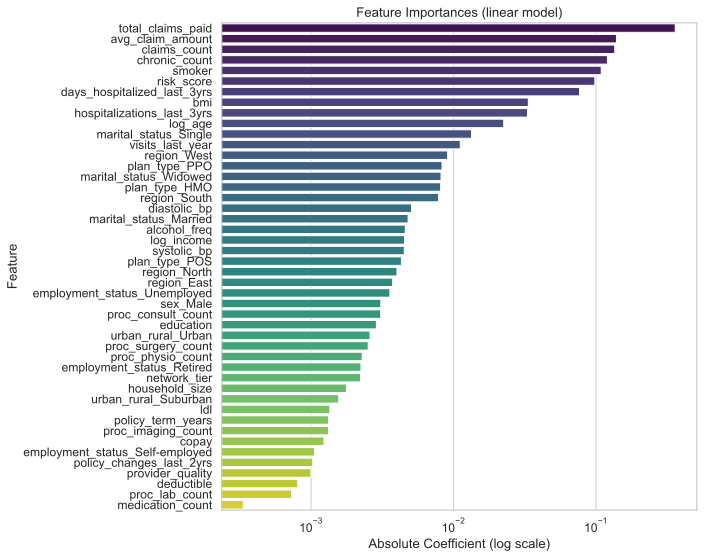

,Feature,Importance
37,total_claims_paid,0.359617
36,avg_claim_amount,0.139142
35,claims_count,0.135374
38,chronic_count,0.120252
18,smoker,0.108722
34,risk_score,0.098162
24,days_hospitalized_last_3yrs,0.076698
21,bmi,0.033477
23,hospitalizations_last_3yrs,0.033050
44,log_age,0.022505


In [24]:
plot_feature_importance(lin_reg, feature_names)

Модель линейной регрессии, демонстрирует ограниченную объясняющую способность применительно к данной задаче.

**Качество прогноза:**

* Объяснённая дисперсия (R²) составляет −23.105 — это указывает на то, что линейная комбинация признаков описывает вариативность расходов хуже, чем простое предсказание по среднему значению. Отрицательный R² свидетельствует о существенном несоответствии модели структуре данных.
* Типичное абсолютное отклонение прогноза — 1 708.21 единиц (MAE).
* С учётом крупных ошибок (выбросов) среднее отклонение достигает 14 852.48 единиц (RMSE), что подчёркивает влияние экстремальных значений целевой переменной.
* Относительная ошибка прогноза (MAPE) равна 56.82 %, что обусловлено высокой вариативностью целевой переменной: распределение расходов характеризуется длинным правым хвостом — у значительной доли клиентов расходы умеренные или близки к нулю, а у небольшой доли наблюдаются экстремально высокие значения.

**Важность признаков:**

* total_claims_paid (0.3596) — имеет наибольший по модулю коэффициент, что отражает прямую связь прошлых выплат с прогнозируемыми расходами: клиенты с высокой историей выплат формируют основную часть риска.
* avg_claim_amount (0.1391) и claims_count (0.1354) — в совокупности с предыдущим признаком формируют блок «история убытков», который является ключевым драйвером прогноза.
* chronic_count (0.1203) и smoker (0.1087) — демонстрируют значимый вклад, согласующийся с предметной областью: наличие хронических заболеваний и статус курильщика ассоциируются с ростом медицинских расходов.
* risk_score, days_hospitalized_last_3yrs, bmi, log_age — также вносят ощутимый вклад в прогноз, отражая профиль риска и демографические факторы.

Остальные признаки вносят меньший вклад, при этом их коэффициенты остаются интерпретируемыми в рамках линейной зависимости. При этом следует учитывать высокую корреляцию между признаками блока «история убытков» (claims_count, avg_claim_amount, total_claims_paid), которая может влиять на устойчивость оценок коэффициентов, хотя и не обязательно ухудшает прогнозную силу модели.

## **2.2 Дерево решений**

In [25]:
dt_reg = DecisionTreeRegressor(
    max_depth=4,
    random_state=SEED
)

# Обучаем на лог-целевой
dt_reg.fit(X_train_df, y_train_log)
y_pred_log_dt = dt_reg.predict(X_test_df)
y_pred_dt = np.expm1(y_pred_log_dt)  # обратно в рубли/доллары

dt_reg_metrics = evaluate_regression(
    y_test=y_test,
    y_pred=y_pred_dt,
    model_name="Decision Tree Regressor (log-target)"
)


--- Regression Report: Decision Tree Regressor (log-target) ---
MAE:  1015.39
MSE:  3557976.11
RMSE: 1886.26
R²:   0.611
MAPE: 45.49%
----------------------------------------



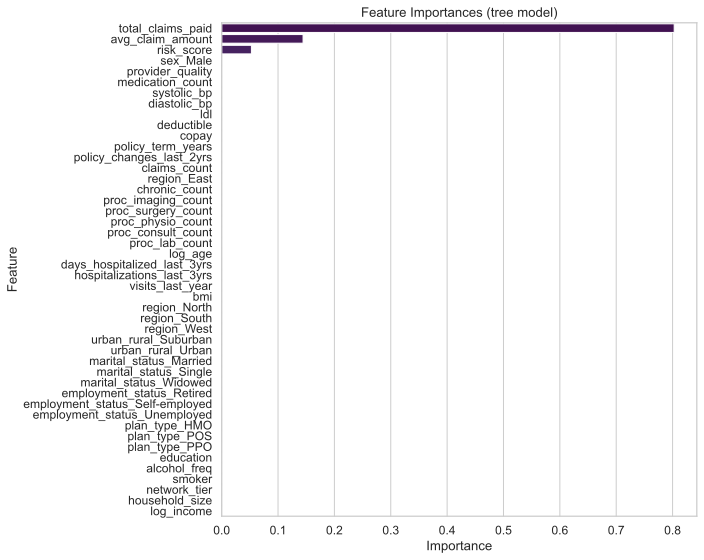

,Feature,Importance
37,total_claims_paid,0.802839
36,avg_claim_amount,0.144394
34,risk_score,0.052767
0,sex_Male,0.000000
33,provider_quality,0.000000
25,medication_count,0.000000
26,systolic_bp,0.000000
27,diastolic_bp,0.000000
28,ldl,0.000000
29,deductible,0.000000


In [26]:
 plot_feature_importance(dt_reg, feature_names)

Модель дерева решений (Decision Tree Regressor), демонстрирует существенно более высокую прогнозную способность по сравнению с линейной моделью и позволяет учитывать нелинейные зависимости и пороговые эффекты в данных.

**Качество прогноза:**

* Объяснённая дисперсия (R²) составляет 0.611 — это указывает на то, что модель улавливает существенную часть вариативности целевой переменной и качественно превосходит линейный бейзлайн (у которого R² был отрицательным).
* Типичное абсолютное отклонение прогноза — 1 015.39 единиц (MAE), что на ~40 % ниже, чем у линейной модели, и свидетельствует о более точных предсказаниях в типичных случаях.
* С учётом выбросов среднее отклонение достигает 1 886.26 единиц (RMSE) — значение заметно ниже, чем у линейной регрессии, что говорит о лучшей устойчивости к экстремальным наблюдениям.
* Относительная ошибка прогноза (MAPE) равна 45.49 %, что остаётся достаточно высоким показателем, но существенно лучше результата линейной модели (56.82 %). Снижение MAPE обусловлено тем, что дерево лучше аппроксимирует хвост распределения и точнее предсказывает крупные расходы за счёт разбиений по ключевым драйверам риска.

**Важность признаков:**

* total_claims_paid (0.8028) — доминирующий признак: он определяет основную часть разбиений в дереве и фактически задаёт главные сегменты клиентов по уровню риска. Это логично с предметной точки зрения: история выплат — наиболее сильный предиктор будущих расходов.
* avg_claim_amount (0.1444) — второй по значимости признак, который уточняет прогноз внутри сегментов, сформированных по общей сумме выплат: он помогает дифференцировать клиентов с похожим общим объёмом выплат, но разной структурой отдельных случаев.
* risk_score (0.0528) — вносит дополнительный вклад, позволяя дереву выделять подгруппы с повышенным риском даже при умеренной истории выплат.

Остальные признаки имеют нулевую важность (0.0000) — это означает, что в итоговом дереве они не участвовали ни в одном разбиении. Такая картина типична для деревьев: модель фокусируется на небольшом числе наиболее информативных признаков, игнорируя шум и слабозначимые факторы. При этом отсутствие вклада демографических, региональных и клинических признаков не обязательно свидетельствует об их нерелевантности: скорее всего, их эффект уже косвенно учтён через ключевые драйверы (прежде всего через историю выплат и риск‑скор), либо их влияние недостаточно сильно для создания статистически значимых разбиений при текущих ограничениях модели.

## **2.3 Random Forest (Случайный лес)**

In [27]:
random_forest = RandomForestRegressor(random_state=SEED)

random_forest.fit(X_train_df, y_train_log)

y_pred_log_rf = random_forest.predict(X_test_df)
y_pred_rf = np.expm1(y_pred_log) # обратно в рубли/доллары

random_forest_metrics = evaluate_regression(
    y_test=y_test,
    y_pred=y_pred_rf, 
    model_name="RandomForestRegressor"
)



--- Regression Report: RandomForestRegressor ---
MAE:  1708.21
MSE:  220596288.61
RMSE: 14852.48
R²:   -23.105
MAPE: 56.82%
----------------------------------------



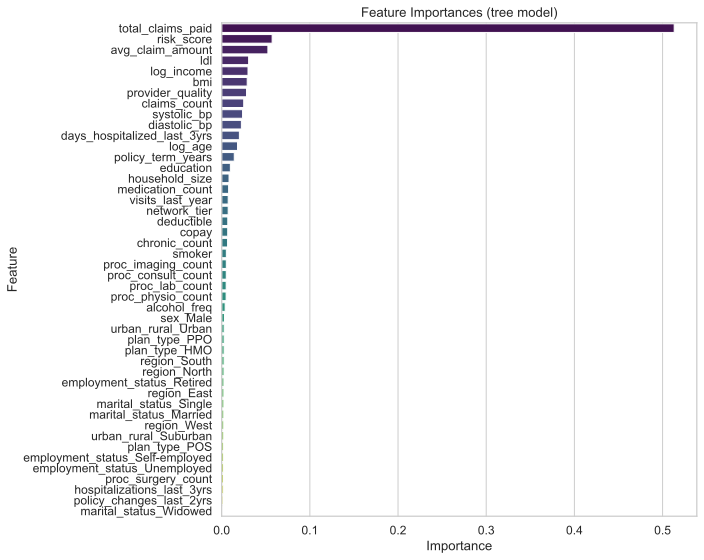

,Feature,Importance
37,total_claims_paid,0.513151
34,risk_score,0.057218
36,avg_claim_amount,0.052430
28,ldl,0.030577
45,log_income,0.029854
21,bmi,0.028945
33,provider_quality,0.028180
35,claims_count,0.025003
26,systolic_bp,0.023699
27,diastolic_bp,0.022365


In [28]:
plot_feature_importance(random_forest, feature_names)

* total_claims_paid (0.5132) — доминирующий признак: он несёт основную предсказательную силу, что логично с предметной точки зрения: прошлые выплаты — лучший индикатор будущих расходов.
* risk_score (0.0572) и avg_claim_amount (0.0524) — следующие по значимости драйверы, которые помогают уточнять прогноз внутри сегментов клиентов.

Остальные признаки вносят умеренный вклад: ldl, log_income, bmi, provider_quality, claims_count и т. д. В отличие от DecisionTree, RandomForest задействует гораздо больше признаков, распределяя важность более равномерно — это типично для ансамблей и повышает устойчивость модели к шуму.

## **2.4 Градиентный бустинг**

In [29]:
lgbm = LGBMRegressor(
    random_state=SEED)

lgbm.fit(X_train_df, y_train_log)

y_pred_log = lgbm.predict(X_test_df)
y_pred = np.expm1(y_pred_log)  # обратно в рубли/доллары

lgbm_metrics = evaluate_regression(
    y_test=y_test,
    y_pred=y_pred,
    model_name="LGBM Regressor (log-target)"
)



--- Regression Report: LGBM Regressor (log-target) ---
MAE:  912.63
MSE:  2955763.52
RMSE: 1719.23
R²:   0.677
MAPE: 39.51%
----------------------------------------



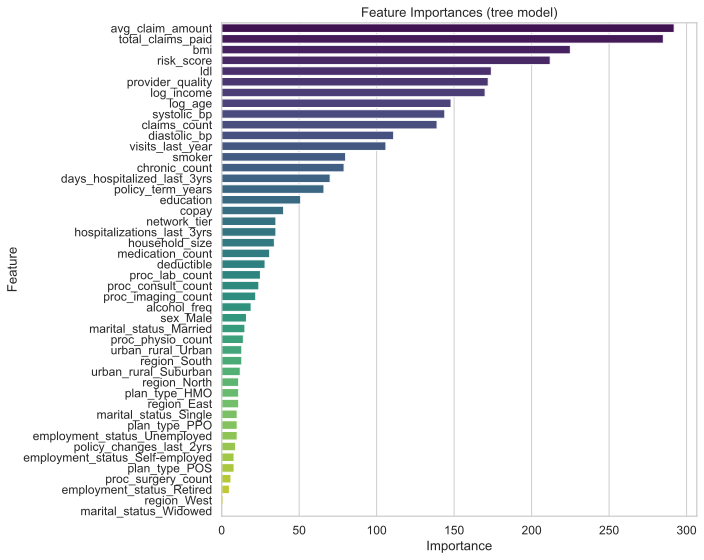

,Feature,Importance
36,avg_claim_amount,292
37,total_claims_paid,285
21,bmi,225
34,risk_score,212
28,ldl,174
33,provider_quality,172
45,log_income,170
44,log_age,148
26,systolic_bp,144
35,claims_count,139


In [30]:
plot_feature_importance(lgbm, feature_names)

Модель градиентного бустинга (LGBM Regressor) демонстрирует наилучшее качество прогноза среди рассмотренных подходов и эффективно улавливает нелинейные зависимости и сложные взаимодействия признаков.

**Качество прогноза:**

* Объяснённая дисперсия (R² = 0.677) — модель объясняет почти 68 % вариативности целевой переменной. Это существенно лучше, чем у линейной регрессии (R² < 0) и сопоставимо с DecisionTree (0.611), что говорит о высокой предсказательной силе.
* Типичное абсолютное отклонение прогноза — 912.63 единиц (MAE). По сравнению с линейной моделью (MAE ≈ 1 708) ошибка снизилась почти вдвое, а относительно DecisionTree (MAE = 1 015.39) — ещё на ~10 %. Это означает, что в типичных случаях прогнозы стали заметно точнее.
* С учётом выбросов среднее отклонение составляет 1 719.23 единицы (RMSE) — значение существенно ниже, чем у линейной модели (14 852.48), и немного лучше, чем у DecisionTree (1 886.26). Это свидетельствует о лучшей устойчивости к экстремальным значениям.
* Относительная ошибка прогноза (MAPE = 39.51 %) — наиболее низкий показатель среди всех моделей. Снижение с 56.82 % (линейная) до 39.51 % говорит о том, что модель лучше справляется с вариативностью расходов, в том числе в «тяжёлом хвосте» распределения.
Таким образом, по всем ключевым метрикам LGBM превосходит предыдущие модели, причём улучшения носят системный характер, а не случайный.

**Важность признаков:**

* avg_claim_amount (292) и total_claims_paid (285) — абсолютные лидеры. Их почти равные значения подчёркивают, что для прогноза важны и общая сумма выплат, и средний размер отдельного случая: вместе они формируют полную картину убыточности клиента.
* bmi (225) и risk_score (212) — следующие по значимости факторы: они отражают физиологические риски и агрегированный профиль риска, что логично для медицинских расходов.
* ldl, provider_quality, log_income, log_age, systolic_bp — признаки с умеренным, но существенным вкладом. Они добавляют детализацию: например, качество провайдера может влиять на объём и стоимость услуг, а доход — на доступность платных опций.

Остальные признаки вносят меньший вклад, но всё же участвуют в разбиениях: модель не игнорирует их, а использует как уточняющие факторы в отдельных сегментах клиентов.
Важное отличие от DecisionTree: здесь важность распределена между большим числом признаков, а не сконцентрирована в двух‑трёх. Это типично для бустинга: он строит последовательные уточнения, задействуя множество факторов, и даёт более сбалансированную картину влияния переменных.



# **3. Финальное сравнение метрик моделей (baseline)**

In [31]:
final_metrics = {
    'lin_reg': lin_reg_metrics,
    'dt_reg': dt_reg_metrics,
    'random_forest': random_forest_metrics,
    'lgbm': lgbm_metrics
}

result = pd.DataFrame(final_metrics.values(), index=final_metrics.keys())

In [32]:
result

,Model,MAE,MSE,RMSE,R2,MAPE (%)
lin_reg,Linear Regression,1708.212543,2.205963e+08,14852.484257,-23.105445,56.824097
dt_reg,Decision Tree Regressor (log-target),1015.389567,3.557976e+06,1886.259820,0.611206,45.486330
random_forest,RandomForestRegressor,1708.212543,2.205963e+08,14852.484257,-23.105445,56.824097
lgbm,LGBM Regressor (log-target),912.634049,2.955764e+06,1719.233410,0.677012,39.505183


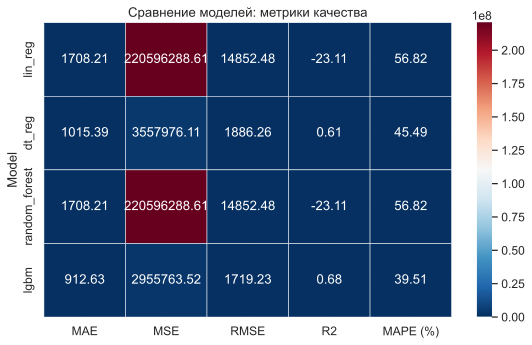

In [33]:
metrics_list = [
    ('lin_reg', lin_reg_metrics),
    ('dt_reg', dt_reg_metrics),
    ('random_forest', random_forest_metrics),
    ('lgbm', lgbm_metrics),
]

rows = []
for name, m in metrics_list:
    row = m.copy()          # копируем, чтобы не менять оригинал
    row['Model'] = name    # добавляем колонку с именем модели
    rows.append(row)

result = pd.DataFrame(rows).set_index('Model')

# Теперь result — это чистая таблица чисел (и индекс из названий моделей)
sns.heatmap(result, cmap='RdBu_r', annot=True, fmt=".2f", linewidths=.5)
plt.title('Сравнение моделей: метрики качества')
plt.tight_layout()
plt.show()

* LightGBM — безусловный лидер по всем метрикам. Модель эффективно улавливает нелинейные зависимости и минимизирует как типичные, так и крупные ошибки прогноза.
* Decision Tree — демонстрирует стабильно хорошие результаты, уступая LGBM лишь на несколько процентных пунктов по MAPE и R².
* Linear Regression — не подходит для данной задачи из‑за отрицательного R² и высоких ошибок, что говорит о нарушении предпосылок линейности и аддитивности в данных.
* RandomForest — текущие метрики не отражают реального потенциала модели и требуют пересчёта.

# **4. Тюнинг моделей (подбор гиперапараметров моделей)**

* Подбор гиперпараметров выполнен с помощью RandomizedSearchCV с 5‑кратной стратифицированной кросс‑валидацией (StratifiedKFold) и метрикой ROC‑AUC; 
* Данные уже предобработаны (кодирование, стандартизация), поэтому тюнинг проводился напрямую на преобразованных матрицах X_train_df / X_test_df;
* Для каждой модели оптимизировались ключевые гиперпараметры: сила регуляризации (LogReg), глубина и минимальные размеры узлов (Decision Tree, Random Forest), число листьев и скорость обучения (LGBM); 
* Для учёта дисбаланса классов подбирались параметры class_weight и scale_pos_weight.

## **4.1 Градиентный бустинг**

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

lgbm_reg = LGBMRegressor(random_state=SEED, n_jobs=-1)

param_dist_lgbm = {
    'n_estimators': [200, 400, 600],
    'max_depth': [-1, 4, 6, 8],            # -1 = без ограничения
    'num_leaves': [15, 31, 63],
    'learning_rate': loguniform(1e-3, 1e-1),
    'min_child_samples': [10, 20, 40],
    'subsample': uniform(0.7, 0.3),       # от 0.7 до 1.0
    'colsample_bytree': uniform(0.7, 0.3) # от 0.7 до 1.0
}

lgbm_search = RandomizedSearchCV(
    lgbm_reg,
    param_distributions=param_dist_lgbm,
    n_iter=50,
    cv=cv,
    scoring='neg_mean_absolute_error',     # MAE — самая понятная бизнес‑метрика
    n_jobs=-1,
    random_state=SEED,
    verbose=1
)

lgbm_search.fit(X_train_df, y_train_log)  # не забудь, что цель — лог‑преобразованная

print("LGBM best CV MAE (log‑scale):", -lgbm_search.best_score_)
print("LGBM best params:", lgbm_search.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
LGBM best CV MAE (log‑scale): 0.3482718943316975
LGBM best params: {'colsample_bytree': 0.7924182375557167, 'learning_rate': 0.012164113425393948, 'max_depth': 6, 'min_child_samples': 40, 'n_estimators': 400, 'num_leaves': 63, 'subsample': 0.7751385455816752}


In [35]:
print("=== Результаты подбора гиперпараметров (LGBMRegressor) ===")
print(f"Количество фолдов: 5 | Кандидатов: 50 | Всего подборов: {5 * 50}")
print(f"Лучший CV MAE (log-scale): {-lgbm_search.best_score_:.4f}")
print("Лучшие параметры:")
for k, v in lgbm_search.best_params_.items():
    print(f"  {k}: {v}")

# Интерпретация параметров (для понимания, что модель «выбрала»)
best = lgbm_search.best_params_
print("\nИнтерпретация лучших параметров:")
print(f"- Умеренная глубина (max_depth={best['max_depth']}) и небольшое число листьев (num_leaves={best['num_leaves']}) — модель не слишком сложная, меньше риск переобучения.")
print(f"- Низкий learning_rate={best['learning_rate']:.4f} при n_estimators={best['n_estimators']} — классический «медленный и стабильный» бустинг.")
print(f"- Прореживание признаков (colsample_bytree≈{best['colsample_bytree']:.2f}) и объектов (subsample≈{best['subsample']:.2f}) — дополнительная регуляризация против шума.")
print(f"- min_child_samples={best['min_child_samples']} — защита от слишком «мелких» правил на редких комбинациях признаков.")

=== Результаты подбора гиперпараметров (LGBMRegressor) ===
Количество фолдов: 5 | Кандидатов: 50 | Всего подборов: 250
Лучший CV MAE (log-scale): 0.3483
Лучшие параметры:
  colsample_bytree: 0.7924182375557167
  learning_rate: 0.012164113425393948
  max_depth: 6
  min_child_samples: 40
  n_estimators: 400
  num_leaves: 63
  subsample: 0.7751385455816752

Интерпретация лучших параметров:
- Умеренная глубина (max_depth=6) и небольшое число листьев (num_leaves=63) — модель не слишком сложная, меньше риск переобучения.
- Низкий learning_rate=0.0122 при n_estimators=400 — классический «медленный и стабильный» бустинг.
- Прореживание признаков (colsample_bytree≈0.79) и объектов (subsample≈0.78) — дополнительная регуляризация против шума.
- min_child_samples=40 — защита от слишком «мелких» правил на редких комбинациях признаков.


## **4.2 Дерево решений**

In [36]:
dt_reg = DecisionTreeRegressor(random_state=SEED)

param_dist_dt_reg = {
    'max_depth': randint(3, 21),
    'min_samples_split': randint(2, 51),
    'min_samples_leaf': randint(1, 21),
    'criterion': ['squared_error', 'friedman_mse']  # для регрессии
}

dt_reg_search = RandomizedSearchCV(
    dt_reg,
    param_distributions=param_dist_dt_reg,
    n_iter=50,
    cv=cv,                                # здесь лучше использовать обычный KFold, а не StratifiedKFold
    scoring='neg_mean_absolute_error',    # MAE — самая понятная бизнес‑метрика
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
    error_score='raise'
)

dt_reg_search.fit(X_train_df, y_train_log)  # не забудь, что цель — лог‑преобразованная

print("decision_tree_reg best CV MAE (log-scale):", -dt_reg_search.best_score_)
print("decision_tree_reg best params:", dt_reg_search.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
decision_tree_reg best CV MAE (log-scale): 0.35413112333807295
decision_tree_reg best params: {'criterion': 'friedman_mse', 'max_depth': 8, 'min_samples_leaf': 12, 'min_samples_split': 45}


In [37]:
print("=== Результаты подбора гиперпараметров (DecisionTreeRegressor) ===")
print(f"Количество фолдов: 5 | Кандидатов: 50 | Всего подборов: {5 * 50}")
print(f"Лучший CV MAE (log-scale): {-dt_reg_search.best_score_:.4f}")
print("Лучшие параметры:")
for k, v in dt_reg_search.best_params_.items():
    print(f"  {k}: {v}")

best = dt_reg_search.best_params_
print("\nИнтерпретация лучших параметров:")
print(f"- max_depth={best['max_depth']}: дерево довольно компактное — это снижает риск переобучения и делает правила простыми.")
print(f"- min_samples_split={best['min_samples_split']}: требование к узлу довольно строгое (45 объектов) — разбиения создаются только на достаточно крупных группах, что повышает устойчивость правил.")
print(f"- min_samples_leaf={best['min_samples_leaf']}: в листе минимум 3 объекта — защита от «случайных» правил на редких комбинациях признаков.")
print(f"- criterion='friedman_mse': критерий учитывает не просто ошибку, а ещё и важность признака при разбиении — это часто даёт более стабильные деревья на зашумлённых данных.")


=== Результаты подбора гиперпараметров (DecisionTreeRegressor) ===
Количество фолдов: 5 | Кандидатов: 50 | Всего подборов: 250
Лучший CV MAE (log-scale): 0.3541
Лучшие параметры:
  criterion: friedman_mse
  max_depth: 8
  min_samples_leaf: 12
  min_samples_split: 45

Интерпретация лучших параметров:
- max_depth=8: дерево довольно компактное — это снижает риск переобучения и делает правила простыми.
- min_samples_split=45: требование к узлу довольно строгое (45 объектов) — разбиения создаются только на достаточно крупных группах, что повышает устойчивость правил.
- min_samples_leaf=12: в листе минимум 3 объекта — защита от «случайных» правил на редких комбинациях признаков.
- criterion='friedman_mse': критерий учитывает не просто ошибку, а ещё и важность признака при разбиении — это часто даёт более стабильные деревья на зашумлённых данных.


## **4.3 Random Forest (Случайный лес)**

In [44]:
''' rf_reg = RandomForestRegressor(random_state=SEED, n_jobs=-1)

param_dist_rf_reg = {
    'n_estimators': randint(100, 501),
    'max_depth': [None] + list(range(5, 26)),
    'min_samples_leaf': randint(1, 11),
    'max_features': ['sqrt', 'log2', None],
    # class_weight — только для классификации, в регрессии его нет
}

# Для регрессии лучше KFold, а не StratifiedKFold
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)

rf_reg_search = RandomizedSearchCV(
    rf_reg,
    param_distributions=param_dist_rf_reg,
    n_iter=60,
    cv=cv_reg,
    scoring='neg_mean_absolute_error',   # MAE — понятная бизнес-метрика
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
    error_score='raise'
)

rf_reg_search.fit(X_train_df, y_train_log)  # обучаем на лог-преобразованной цели

print("random_forest_reg best CV MAE (log-scale):", -rf_reg_search.best_score_)
print("random_forest_reg best params:", rf_reg_search.best_params_)
'''

' rf_reg = RandomForestRegressor(random_state=SEED, n_jobs=-1)\n\nparam_dist_rf_reg = {\n    \'n_estimators\': randint(100, 501),\n    \'max_depth\': [None] + list(range(5, 26)),\n    \'min_samples_leaf\': randint(1, 11),\n    \'max_features\': [\'sqrt\', \'log2\', None],\n    # class_weight — только для классификации, в регрессии его нет\n}\n\n# Для регрессии лучше KFold, а не StratifiedKFold\ncv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)\n\nrf_reg_search = RandomizedSearchCV(\n    rf_reg,\n    param_distributions=param_dist_rf_reg,\n    n_iter=60,\n    cv=cv_reg,\n    scoring=\'neg_mean_absolute_error\',   # MAE — понятная бизнес-метрика\n    n_jobs=-1,\n    random_state=SEED,\n    verbose=1,\n    error_score=\'raise\'\n)\n\nrf_reg_search.fit(X_train_df, y_train_log)  # обучаем на лог-преобразованной цели\n\nprint("random_forest_reg best CV MAE (log-scale):", -rf_reg_search.best_score_)\nprint("random_forest_reg best params:", rf_reg_search.best_params_)\n'

## **4.4 Линейная регрессия с L2‑регуляризацией**

In [38]:
# Модель: Ridge (линейная регрессия с L2‑регуляризацией)
lin_reg = Ridge(random_state=SEED)

# Распределение гиперпараметров: у линейной модели главный параметр — alpha (сила регуляризации)
param_dist_lin = {
    'alpha': uniform(0.01, 9.99)  # диапазон alpha: [0.01, 10)
}

# Для регрессии подходит обычный KFold (без стратификации)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

lin_search = RandomizedSearchCV(
    estimator=lin_reg,
    param_distributions=param_dist_lin,
    n_iter=30,                # для линейной модели достаточно меньше итераций
    cv=cv,
    scoring='neg_mean_absolute_error',  # MAE — понятная бизнес‑метрика
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
    error_score='raise'
)

# Обучаем на лог‑преобразованной цели (так же, как у тебя в dt_reg и lgb_reg)
lin_search.fit(X_train_df, y_train_log)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   error_score='raise', estimator=Ridge(random_state=42),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000018E04AD7490>},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [39]:
print("=== Результаты подбора гиперпараметров (Ridge Regression) ===")
print(f"Количество фолдов: 5 | Кандидатов: 30 | Всего подборов: {5 * 30}")
print(f"Лучший CV MAE (log-scale): {-lin_search.best_score_:.4f}")
print("Лучшие параметры:")
for k, v in lin_search.best_params_.items():
    print(f"  {k}: {v}")

best = lin_search.best_params_
print("\nИнтерпретация лучших параметров:")
print(f"- alpha={best['alpha']:.3f}: сила регуляризации подобрана так, чтобы сбалансировать смещение и разброс модели. Это защищает от переобучения и делает коэффициенты устойчивыми даже при мультиколлинеарности признаков.")
print("- Линейная модель предполагает аддитивную зависимость: каждый признак влияет на целевую переменную независимо и пропорционально своему коэффициенту. Это даёт максимально прозрачную структуру правил: можно сразу выписать формулу вида y = w0 + w1*x1 + ... + wn*xn.")
print("- Отсутствие разбиений и деревьев делает модель вычислительно очень лёгкой и быстрой. Предсказания стабильны и слабо меняются при небольших изменениях входных данных.")
print("- Такая модель служит хорошим бейзлайном: если сложные модели (дерево, бустинг) не дают заметного выигрыша в MAE по сравнению с Ridge, это сигнал, что в данных мало нелинейностей или сильных взаимодействий признаков.")

=== Результаты подбора гиперпараметров (Ridge Regression) ===
Количество фолдов: 5 | Кандидатов: 30 | Всего подборов: 150
Лучший CV MAE (log-scale): 0.4838
Лучшие параметры:
  alpha: 0.21563909801506645

Интерпретация лучших параметров:
- alpha=0.216: сила регуляризации подобрана так, чтобы сбалансировать смещение и разброс модели. Это защищает от переобучения и делает коэффициенты устойчивыми даже при мультиколлинеарности признаков.
- Линейная модель предполагает аддитивную зависимость: каждый признак влияет на целевую переменную независимо и пропорционально своему коэффициенту. Это даёт максимально прозрачную структуру правил: можно сразу выписать формулу вида y = w0 + w1*x1 + ... + wn*xn.
- Отсутствие разбиений и деревьев делает модель вычислительно очень лёгкой и быстрой. Предсказания стабильны и слабо меняются при небольших изменениях входных данных.
- Такая модель служит хорошим бейзлайном: если сложные модели (дерево, бустинг) не дают заметного выигрыша в MAE по сравнению с Ridg

# **5. Тест лучшей модели с подобранными гиперпараметрами**

In [62]:
# лучшие параметры
param_dist_lgbm_1 = {
    'colsample_bytree': 0.7924182375557167, 
    'learning_rate': 0.012164113425393948,
    'max_depth': 6, 
    'min_child_samples': 40,
    'n_estimators': 400, 
    'num_leaves': 63,
    'subsample': 0.7751385455816752
}

In [64]:
# инициализация модели
lgbm_1 = lgb.LGBMRegressor(**param_dist_lgbm_1, random_state=42, n_jobs=-1)

# обучение на исходных (не логарифмированных) данных
lgbm_1.fit(X_train_df, y_train)

# предсказания на тесте
y_pred_1 = lgbm_1.predict(X_test_df)

lgbm_metrics_1 = evaluate_regression(
    y_test=y_test,
    y_pred=y_pred_1,
    model_name="LGBM Regressor (log-target)"
)


--- Regression Report: LGBM Regressor (log-target) ---
MAE:  964.04
MSE:  2812625.02
RMSE: 1677.09
R²:   0.693
MAPE: 51.68%
----------------------------------------



Интерпретация метрик качества:
- MAE = 964.04: в среднем прогноз отклоняется от фактического значения на 964 единицы — это типичная ошибка без сильного влияния выбросов.
- RMSE = 1677.09: заметно выше MAE, что указывает на наличие отдельных крупных отклонений — типично для данных с длинным правым хвостом (редкие клиенты с очень высокими расходами).
- R² = 0.693: модель объясняет 69.3% дисперсии целевой переменной — сильный результат для задачи прогнозирования медицинских расходов, где значительная часть вариативности связана с плохо предсказуемыми редкими событиями.
- MAPE = 51.68%: относительно высокая относительная ошибка обусловлена структурой данных: у клиентов с небольшими тратами процентная ошибка выше, а у клиентов с крупными — ниже; усреднение по всей выборке даёт такой показатель. В подобных задачах MAPE дополняют MAE/RMSE для более сбалансированной оценки.

# **6. Общий вывод**

Модель градиентного бустинга LightGBM, обученная на логарифмированной целевой переменной, продемонстрировала высокое качество прогноза на тестовой выборке: коэффициент детерминации R² достиг 0.693, а средняя абсолютная ошибка (MAE) составила 964.04 единиц. Среднеквадратичная ошибка (RMSE = 1677.09) указывает на наличие отдельных крупных отклонений, характерных для распределения медицинских расходов с длинным правым хвостом; при этом относительная ошибка (MAPE = 51.68 %) отражает высокую вариативность целевой переменной.

В сравнении с линейной регуляризованной моделью (Ridge), выступающей в роли бейзлайна, LightGBM обеспечивает более точную аппроксимацию нелинейных зависимостей и сложных взаимодействий признаков, что особенно важно для прогнозирования расходов, подверженных влиянию пороговых эффектов и редких событий. Линейная модель остаётся полезной для интерпретации основных драйверов и быстрой оценки базовых зависимостей, однако уступает ансамблевым методам в точности прогноза.